### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Homework 6
### Due: Wed. Nov 4, at 11.59pm CT
---

This problem has to do with density estimation and clustering. 

1. Read in `hw6_data_1.npy`. The dataset should consist of $1000$ samples with $2$ features. Note that the last column are the labels, not another feature. Make a $2$-D scatter plot of the data colored by their labels. 


2. Start with kernel density estimation on the data set. First, perform a grid search $5$-fold cross-validation to find the best bandwidth, testing $30$ bandwidths between $0.1$ and $1.0$. What is this best bandwidth? Using this best bandwidth, plot the two-dimensional kernel density estimate of the distribution. 


3. Now try a nearest neighbors approach to estimating the density. Use the Bayesian nearest neighbors option. Plot the estimated distribution. What value of $k$ neighbors do you need to make the plot look similar to your KDE distribution?


4. Now fit a Gaussian mixture model. Compute the AIC and BIC for the number of GMM components between $1$ and $10$. Plot these AIC and BIC values as a function of number of components. What is the optimal number according to the BIC? Fit the data set with this optimal number of GMM components, and create a new plot that shows the data set, the GMM component mean locations, and the $2$-sigma GMM component ellipses. *(Use the code below to help with plotting the ellipses.)*

In [2]:
# Kludge to fix the bug with draw_ellipse in astroML
from matplotlib.patches import Ellipse

def draw_ellipse(mu, C, scales=[1, 2, 3], ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()

    # find principal components and rotation angle of ellipse
    sigma_x2 = C[0, 0]
    sigma_y2 = C[1, 1]
    sigma_xy = C[0, 1]

    alpha = 0.5 * np.arctan2(2 * sigma_xy,
                          (sigma_x2 - sigma_y2))
    tmp1 = 0.5 * (sigma_x2 + sigma_y2)
    tmp2 = np.sqrt(0.25 * (sigma_x2 - sigma_y2) ** 2 + sigma_xy ** 2)

    sigma1 = np.sqrt(tmp1 + tmp2)
    sigma2 = np.sqrt(tmp1 - tmp2)

    for scale in scales:
        ax.add_patch(Ellipse(xy=(mu[0], mu[1]),
                          width=2 * scale * sigma1, height=2 * scale * sigma2,
                          angle=alpha * 180. / np.pi,
                          **kwargs))

5. Now try Kmeans clustering with $5$ clusters. 
    - Use the `StandardScalar` to scale the data.
    - Fit the Kmeans model.
    - Find the cluster centers, and then inverse transform thse cluster centers back to the original unscaled coordinates.
    - Predict the labels for the scaled data.
    - Finally, make a two-panel side by side plot showing (a) the original data colored by its labels, then (b) the data colored by the Kmeans predicted labels, with cluster centers superposed.

### Solution

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from matplotlib.patches import Ellipse
from astroML.density_estimation import KNeighborsDensity

In [13]:
import warnings

warnings.filterwarnings("ignore", category=UserWarning, message=".*memory leak.*")

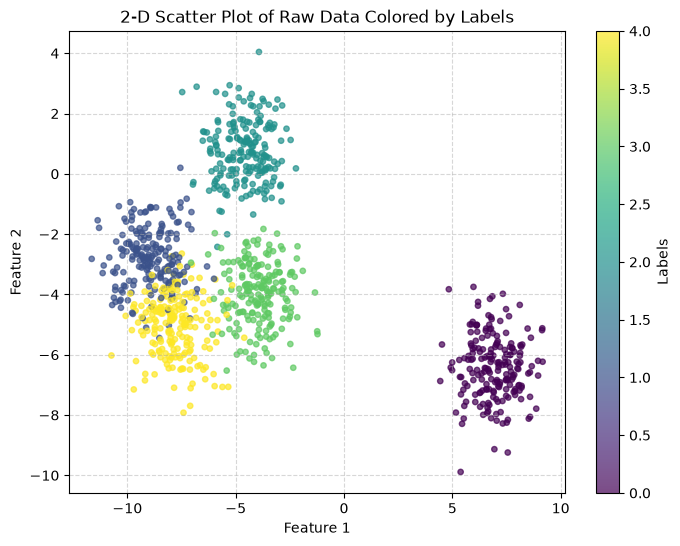

In [2]:
#---Pt.1---
data = np.load("C:/Users/aaron/Git/repos/astrostats_ttu_fall26/coursework/student_folders/aaron_hawley/homeworks/hw_data/hw6_data_1.npy")

X = data[:, :2]
y = data[:, 2]

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=15, alpha=0.7)
plt.colorbar(scatter, label='Labels')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('2-D Scatter Plot of Raw Data Colored by Labels')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

The best bandwidth found via 5-fold CV is: 0.4724


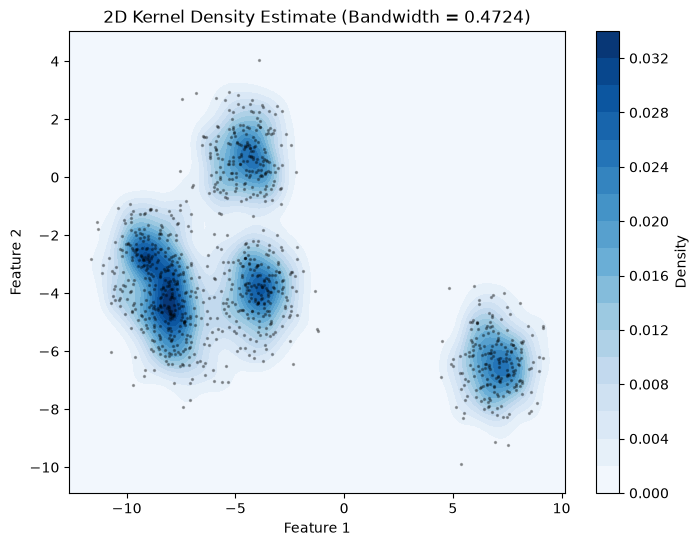

In [3]:
#---Pt.2---
bandwidths = np.linspace(0.1, 1.0, 30)
grid = GridSearchCV(KernelDensity(kernel='gaussian'), 
                    {'bandwidth': bandwidths}, 
                    cv=5)
grid.fit(X)

best_bandwidth = grid.best_params_['bandwidth']
print(f"The best bandwidth found via 5-fold CV is: {best_bandwidth:.4f}")

# Define a grid grid to plot the density estimate
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# Fit KDE with best bandwidth and evaluate over the mesh grid
kde = KernelDensity(kernel='gaussian', bandwidth=best_bandwidth)
kde.fit(X)
log_density = kde.score_samples(grid_points)
density = np.exp(log_density).reshape(xx.shape)

# Plot the 2D Kernel Density Estimate
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, density, levels=20, cmap='Blues')
plt.colorbar(label='Density')
plt.scatter(X[:, 0], X[:, 1], c='black', s=2, alpha=0.3)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title(f'2D Kernel Density Estimate (Bandwidth = {best_bandwidth:.4f})')
plt.show()

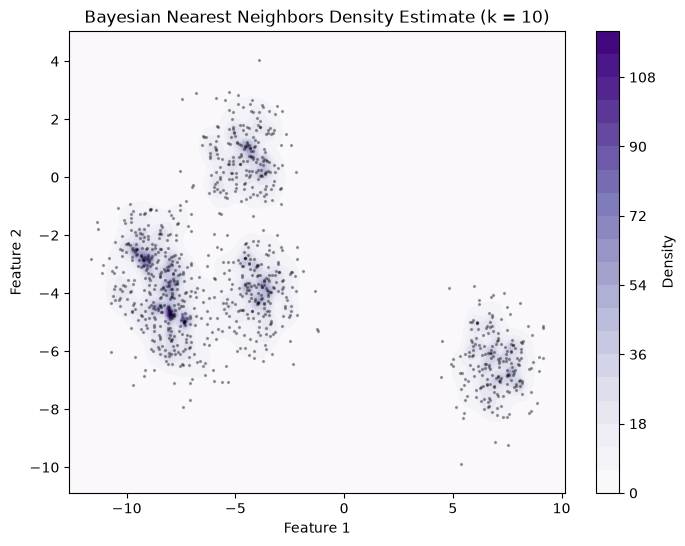

In [6]:
#---Pt.3---
k_neighbors = 10 

knn_density = KNeighborsDensity(method='bayesian', n_neighbors=k_neighbors)
knn_density.fit(X)

density_knn = knn_density.eval(grid_points).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, density_knn, levels=20, cmap='Purples')
plt.colorbar(label='Density')
plt.scatter(X[:, 0], X[:, 1], c='black', s=2, alpha=0.3)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title(f'Bayesian Nearest Neighbors Density Estimate (k = {k_neighbors})')
plt.show()

In [8]:
def draw_ellipse(mu, C, scales=[1, 2, 3], ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()
        
    sigma_x2 = C[0, 0]
    sigma_y2 = C[1, 1]
    sigma_xy = C[0, 1]
    
    alpha = 0.5 * np.arctan2(2 * sigma_xy, (sigma_x2 - sigma_y2))
    tmp1 = 0.5 * (sigma_x2 + sigma_y2)
    tmp2 = np.sqrt(0.25 * (sigma_x2 - sigma_y2) ** 2 + sigma_xy ** 2)
    
    sigma1 = np.sqrt(tmp1 + tmp2)
    sigma2 = np.sqrt(tmp1 - tmp2)
    
    for scale in scales:
        ax.add_patch(Ellipse(xy=(mu[0], mu[1]),
                             width=2 * scale * sigma1, height=2 * scale * sigma2,
                             angle=alpha * 180. / np.pi,
                             **kwargs))

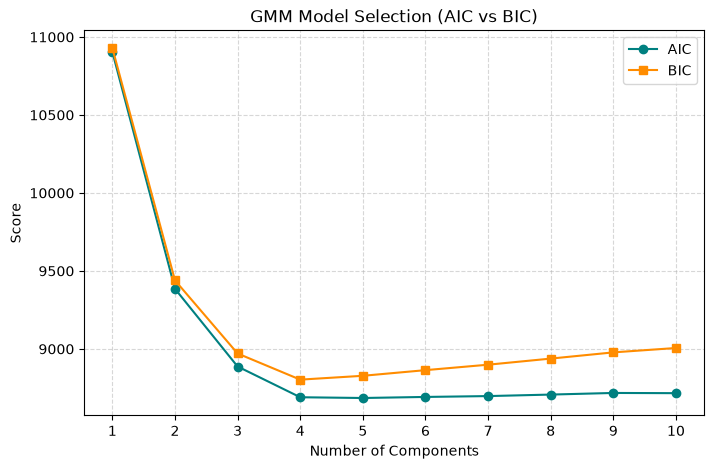

The optimal number of components according to BIC is: 4


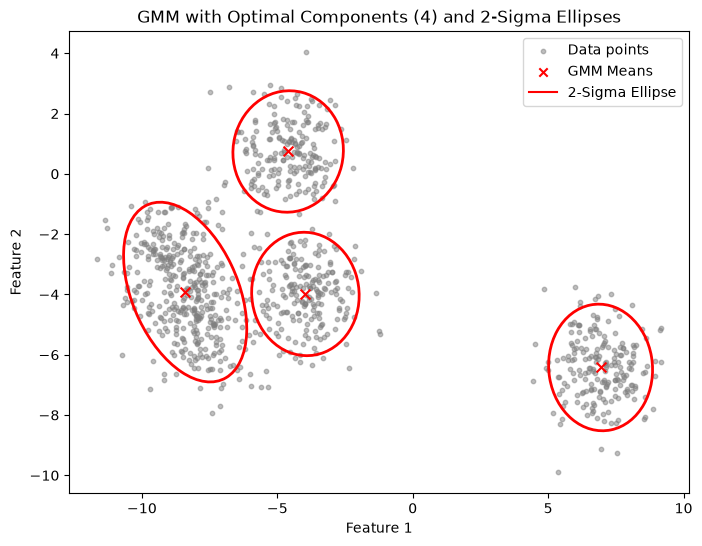

In [14]:
#---Pt.4---
n_components_range = range(1, 11)
aic_values = []
bic_values = []

for n in n_components_range:
    gmm = GaussianMixture(n_components=n, random_state=42)
    gmm.fit(X)
    aic_values.append(gmm.aic(X))
    bic_values.append(gmm.bic(X))

plt.figure(figsize=(8, 5))
plt.plot(n_components_range, aic_values, label='AIC', marker='o', color='teal')
plt.plot(n_components_range, bic_values, label='BIC', marker='s', color='darkorange')
plt.xlabel('Number of Components')
plt.ylabel('Score')
plt.title('GMM Model Selection (AIC vs BIC)')
plt.xticks(n_components_range)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

optimal_n = n_components_range[np.argmin(bic_values)]
print(f"The optimal number of components according to BIC is: {optimal_n}")

gmm_optimal = GaussianMixture(n_components=optimal_n, random_state=42)
gmm_optimal.fit(X)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X[:, 0], X[:, 1], c='gray', s=10, alpha=0.5, label='Data points')

for i in range(optimal_n):
    mu = gmm_optimal.means_[i]
    C = gmm_optimal.covariances_[i]
    
    # Plot component mean location
    ax.scatter(mu[0], mu[1], c='red', marker='x', s=50, zorder=10)
    
    # Draw 2-sigma GMM component ellipses
    draw_ellipse(mu, C, scales=[2], ax=ax, edgecolor='red', facecolor='none', lw=2, zorder=5)

# Label the plot components uniquely for reference
ax.scatter([], [], c='red', marker='x', label='GMM Means')
ax.plot([], [], c='red', label='2-Sigma Ellipse')

ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_title(f'GMM with Optimal Components ({optimal_n}) and 2-Sigma Ellipses')
ax.legend()
plt.show()

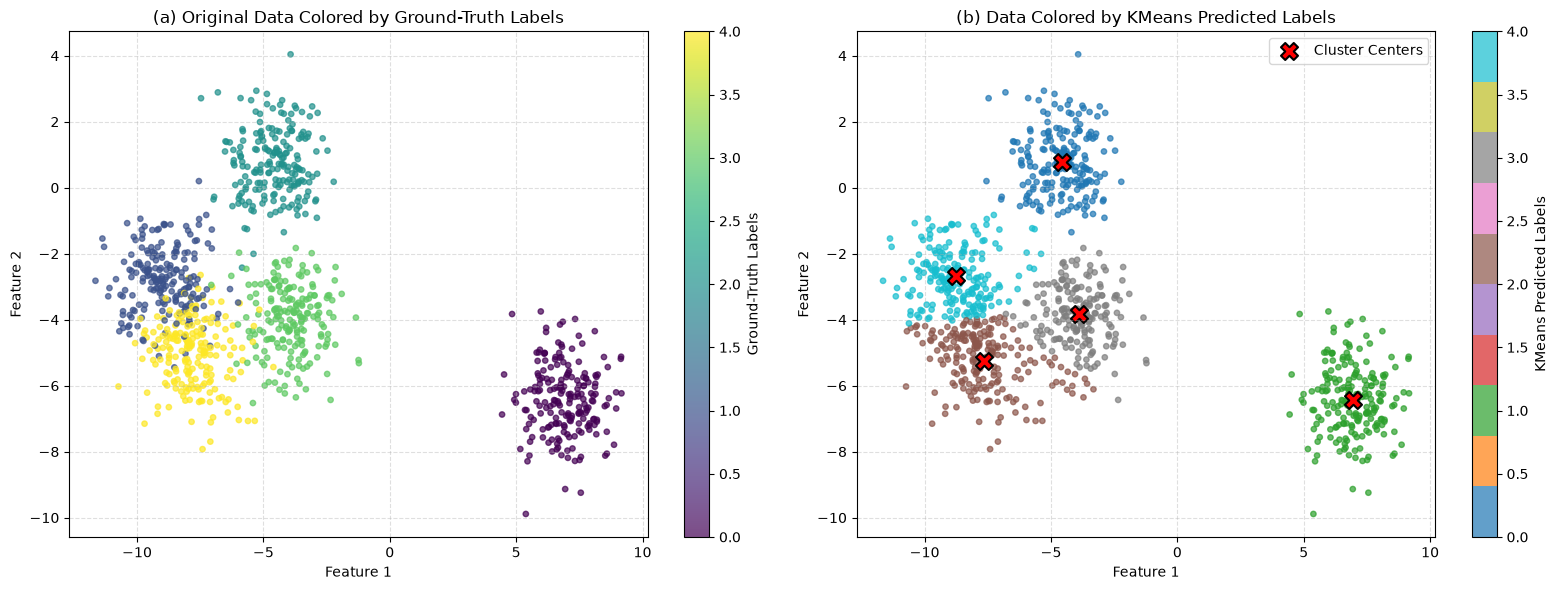

In [15]:
#---Pt.5---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=5, random_state=42, n_init='auto')
kmeans.fit(X_scaled)

scaled_centers = kmeans.cluster_centers_
unscaled_centers = scaler.inverse_transform(scaled_centers)

predicted_labels = kmeans.labels_

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

scatter1 = ax1.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=15, alpha=0.7)
fig.colorbar(scatter1, ax=ax1, label='Ground-Truth Labels')
ax1.set_xlabel('Feature 1')
ax1.set_ylabel('Feature 2')
ax1.set_title('(a) Original Data Colored by Ground-Truth Labels')
ax1.grid(True, linestyle='--', alpha=0.4)

scatter2 = ax2.scatter(X[:, 0], X[:, 1], c=predicted_labels, cmap='tab10', s=15, alpha=0.7)
ax2.scatter(unscaled_centers[:, 0], unscaled_centers[:, 1], c='red', marker='X', s=150, 
            edgecolor='black', linewidth=1.5, label='Cluster Centers')
fig.colorbar(scatter2, ax=ax2, label='KMeans Predicted Labels')
ax2.set_xlabel('Feature 1')
ax2.set_ylabel('Feature 2')
ax2.set_title('(b) Data Colored by KMeans Predicted Labels')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()